<a href="https://colab.research.google.com/github/FernandanFerreira/projeto-ebac-estatistica/blob/main/Profissao_Cientista_de_Dados_M13_Projeto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from matplotlib.ticker import FuncFormatter

In [133]:
df = pd.read_csv("/content/base_dados_modulo.csv", delimiter=',')

df

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
...,...,...,...,...,...,...,...
1102,"Helado bresler pote cassata 2,4l",Bresler,0,4359,5449,1090,congelados
1103,"Helado Trisabor chocolate lúcuma y manjar 2,4 L",Bresler,0,4359,5449,1090,congelados
1104,Shampoo Reconstrucción Completa 400 ml,Dove,0,2690,3849,1159,belleza-y-cuidado-personal
1105,Acondicionador Hidratación Intensa 400 ml,Dove,0,2690,3849,1159,belleza-y-cuidado-personal


## 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto. Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [134]:
media_ctg = (
    df.groupby('Categoria', as_index=False)['Preco_Normal']
    .mean()
    .round(2)
    .rename(columns={'Preco_Normal': 'Media_Preco_Normal'})
    .sort_values('Media_Preco_Normal', ascending=False)
)

print(media_ctg)

                    Categoria  Media_Preco_Normal
1          comidas-preparadas             3095.04
5                     lacteos             2385.22
2                  congelados             2108.04
0  belleza-y-cuidado-personal             1783.56
3                      frutas             1724.47
6                    verduras             1343.30
4        instantaneos-y-sopas              765.49


In [135]:
mediana_ctg = (
    df.groupby('Categoria', as_index=False)['Preco_Normal']
    .median()
    .round(2)
    .rename(columns={'Preco_Normal': 'Mediana_Preco_Normal'})
    .sort_values('Mediana_Preco_Normal', ascending=False)
)

print(mediana_ctg)

                    Categoria  Mediana_Preco_Normal
1          comidas-preparadas                3290.0
0  belleza-y-cuidado-personal                1569.0
2                  congelados                1519.0
3                      frutas                1195.0
6                    verduras                1180.0
5                     lacteos                 989.0
4        instantaneos-y-sopas                 439.0


A maioria das categorias apresentam as médias acima das medianas, inferindo que produtos com preços mais caros estão influenciando a média. Em especial a categoria *Lácteos*, a média está 141% acima da mediana - R$2385,22 e R$989,00, respectivamente - isso nos indica que há produtos dentro da categoria que possuem valores maiores comparado aos demais.

Em contrapartida, categorias como *Comidas Preparadas* e *Verduras* possuem valores de média e mediana relativamente próximos, indicando uma distribuição de preços mais equilibrada ou homogênea.

## 2 - Traga o desvio padrão por categoria de produto. Qual o comportamento da média e mediana nas categorias com maior desvio?

In [136]:
std_ctg = (
    df.groupby('Categoria', as_index=False)['Preco_Normal']
    .agg(Media='mean', Mediana='median', Desvio_Padrao='std')
    .sort_values('Desvio_Padrao', ascending=False)
    .round(2)
)

std_ctg

,Categoria,Media,Mediana,Desvio_Padrao
5,lacteos,2385.22,989.0,3925.82
0,belleza-y-cuidado-personal,1783.56,1569.0,2210.04
2,congelados,2108.04,1519.0,2111.54
1,comidas-preparadas,3095.04,3290.0,2019.91
3,frutas,1724.47,1195.0,1639.15
4,instantaneos-y-sopas,765.49,439.0,1170.23
6,verduras,1343.30,1180.0,1012.70


As categorias com maior desvio padrão possuem o valor da média maior que a mediana. Entre as categorias com maior desvio padrão, a de *Lácteos* ganha destaque, seu desvio é notoriamente maior que a média (3925.82 e 2385.22, respectivamente), isso nos indica uma grande amplitude entre os produtos mais baratos e mais caros dessa categoria, ocasionando grande variabilidade.

## 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

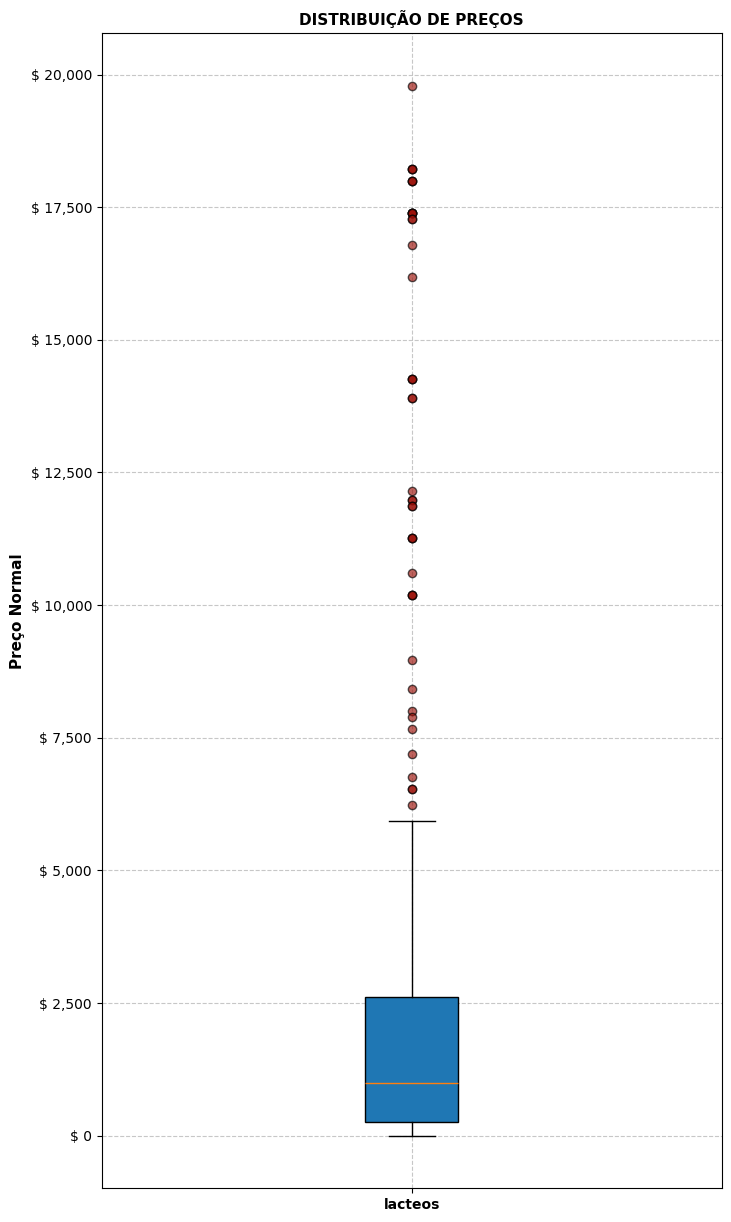

In [137]:
ctg_maior_std = df.iloc[0]['Categoria']

preco_ctg_maior_std = df.loc[df['Categoria'] == ctg_maior_std, 'Preco_Normal']

# Criação gráfico
fig, ax = plt.subplots(figsize=(8, 15))
ax.boxplot(preco_ctg_maior_std, patch_artist=True, flierprops=dict(markerfacecolor='#9B1008', alpha=0.65))

#Configuração titulos e legendas
ax.set_title('DISTRIBUIÇÃO DE PREÇOS', fontsize=11, fontweight='bold')
ax.set_ylabel('Preço Normal', fontsize=11, fontweight='bold')
ax.set_xticklabels([ctg_maior_std], fontweight='bold')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'$ {x:,.0f}'))



plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

A caixa se concentra na parte inferior do gráfico, indicando que a grande maioria dos produtos possuem preços baixos. A linha da mediana localizada dentro da caixa está descentralizada, indicando que os dados são assimétricos e reforçando que metade dos produtos possuem valores mais baixos.

Porém, podemos observar uma grande quantidade de pontos fora do limite superior, considerados valores atípicos de preços. Estes outliers estendem em uma ampla faixa do eixo de preço, justificando os valores elevados de desvio padrão.


## 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

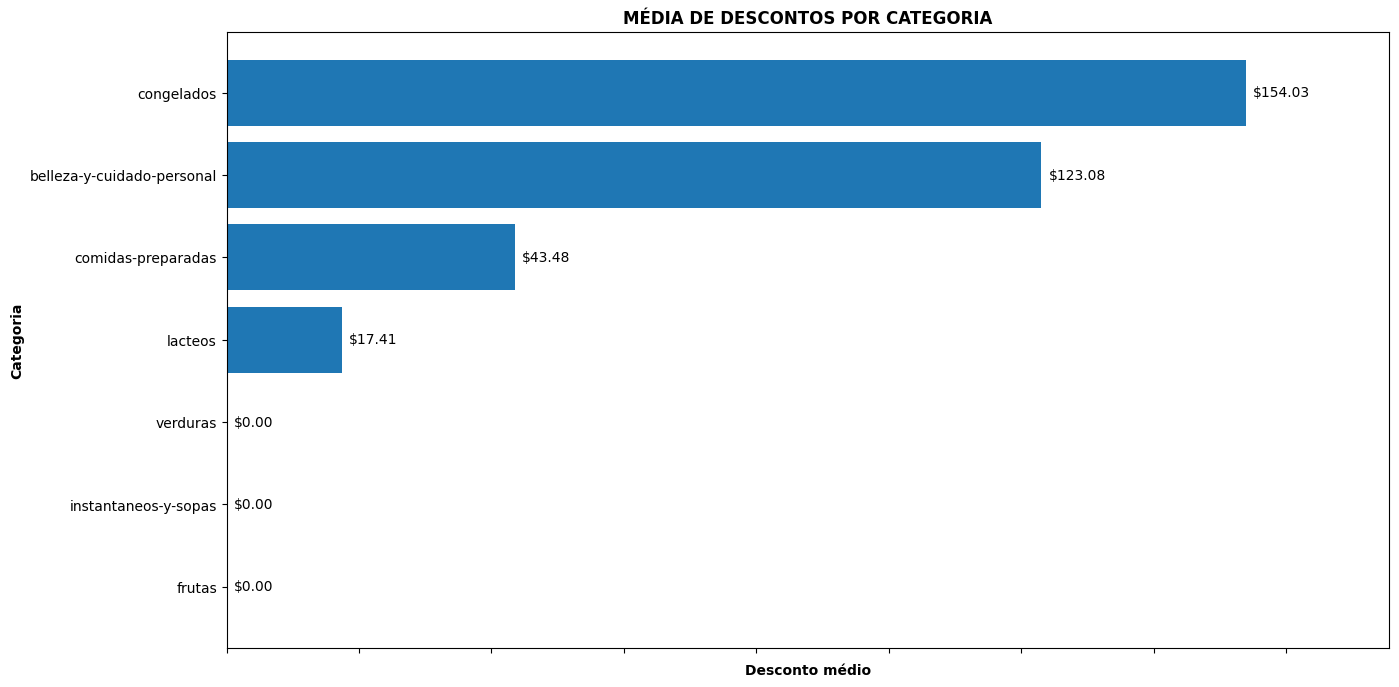

In [138]:

media_desconto_ctg = (
    df.groupby('Categoria', as_index=False)['Desconto']
    .mean()
    .sort_values('Desconto', ascending=True)
    .round(2)
)

# Gerar gráfico
fig, ax = plt.subplots(figsize=(15,8))
barras = ax.barh(
    media_desconto_ctg['Categoria'],
    media_desconto_ctg['Desconto']
)

# Ajuste das bordas do gráfico

max_val = media_desconto_ctg['Desconto'].max()
ax.set_xlim(0, max_val*1.14)

# Valores da barra
ax.bar_label(barras, labels=[f'${x:,.2f}' for x in media_desconto_ctg['Desconto']], padding = 5)

#Configuração titulos e legendas
ax.set_title('MÉDIA DE DESCONTOS POR CATEGORIA', fontweight='bold')
ax.set_ylabel('Categoria', fontweight = 'bold')
ax.set_xlabel('Desconto médio', fontweight = 'bold')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'$ {x:,.0f}'))
ax.set_xticklabels([])

plt.show()


## 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [139]:
mapa_descontos = (
    df.groupby(['Categoria', 'Marca'], as_index=False)
      .agg(
          Desconto_Medio=('Desconto', 'mean'),
          Quantidade_Produtos=('title', 'count')
      )
)

fig_mapa = px.treemap(
    mapa_descontos,
    values='Quantidade_Produtos',
    path=[px.Constant('Mercado'), 'Categoria', 'Marca'],
    color='Desconto_Medio',
    color_continuous_scale='RdYlGn',
    custom_data=['Desconto_Medio', 'Quantidade_Produtos'],
    title='Mapa interativo: desconto médio por categoria e marca'
)

fig_mapa.update_traces(
    hovertemplate=(
        "<b>%{label}</b><br>"
        "Desconto médio: $ %{customdata[0]:,.2f}<br>"
        "Quantidade de produtos: %{customdata[1]}"
        "<extra></extra>"
    )
)

fig_mapa.update_layout(
    margin=dict(t=60, l=10, r=10, b=10),
    coloraxis_colorbar_title='Desconto médio',
    height=650
)

fig_mapa
